# 2. Recocido simulado

El recocido simulado (*simulated annealing*) es un método de trayectoria que, en cada iteración, propone una solución vecina de la actual y decide si la acepta. Las mejoras se aceptan siempre y los empeoramientos se aceptan con una probabilidad que depende de cuánto empeora la solución y de un parámetro llamado temperatura, que disminuye a lo largo de la búsqueda. Al comienzo, con temperatura alta, el método acepta casi cualquier movimiento y explora; al final, con temperatura baja, solo acepta mejoras y se comporta como un ascenso de colinas (*hill climbing*).

El capítulo empieza por el origen del método y por la regla de aceptación, y sigue con cuatro ejemplos: la curva de probabilidad de aceptación para varias temperaturas, la minimización de la función de Rosenbrock en dos variables continuas, el problema de las $n$ reinas con una representación de permutación y el ajuste de los hiperparámetros de un bosque aleatorio, en una versión con un solo operador de vecindad y en otra con tres.

Las diapositivas de clase sobre el método están en [Recocido_simulado_diapositivas.pdf](../material/Recocido_simulado_diapositivas.pdf).

## Del recocido de metales al algoritmo de Metropolis

El nombre viene de la metalurgia. El trabajo en frío de un metal causa o aumenta los defectos de su estructura cristalina, y para corregirlos se hace un recocido (*annealing*). El metal se calienta hasta, aproximadamente, 0,4 veces su temperatura de fusión, de modo que los iones pueden moverse libremente, y después se enfría despacio. Durante el enfriamiento los iones van ocupando posiciones estables y de baja energía, aunque por su movimiento pueden pasar temporalmente por posiciones de alta energía. Así, una estructura cristalina inicialmente frágil llega a una configuración mucho mejor, atravesando estados buenos y malos.

Metropolis y sus coautores (Metropolis et al., 1953) propusieron simular ese proceso con un algoritmo de Monte Carlo. Un material tiene una probabilidad proporcional a $e^{-E/(k_B T)}$ de estar en un macroestado de energía $E$, donde $k_B$ es la constante de Boltzmann; cuanto mayor es la temperatura, mayor es la probabilidad de estar en un estado de alta energía. Si $pos$ es la configuración actual y $pos'$ una posible configuración nueva, la diferencia de energía es

$$\Delta E = E(pos') - E(pos),$$

y la probabilidad de aceptar la nueva configuración es

$$P(\Delta E) = \begin{cases} e^{-\Delta E/(k_B T)} & \text{si } \Delta E > 0,\\ 1 & \text{en otro caso.}\end{cases}$$

## El recocido simulado

La simulación de Metropolis muestra cómo un sistema físico encuentra estados de baja energía y escapa de los óptimos locales aceptando, de vez en cuando, estados peores. Kirkpatrick, Gelatt y Vecchi (1983) trasladaron la idea a la optimización. El recocido simulado es, en esencia, un ascenso de colinas que a veces acepta estados peores siguiendo la regla de Metropolis, lo que reduce el riesgo de convergencia prematura que tiene el ascenso de colinas.

Para minimizar una función $f$, la energía se sustituye por el valor de la función objetivo. Si $x$ es la solución actual y $x'$ la candidata,

$$\Delta E = f(x') - f(x), \qquad P(\Delta E) = \begin{cases} e^{-\Delta E/T} & \text{si } \Delta E > 0,\\ 1 & \text{en otro caso.}\end{cases}$$

La constante $k_B$ se elimina porque en optimización no hace falta y complica la interpretación de la probabilidad de aceptación. En todos los códigos de este capítulo la regla se escribe como `delta_E < 0 or np.random.random() < np.exp(-delta_E / T)`, que es la misma de la fórmula, porque cuando $\Delta E = 0$ la exponencial vale 1 y el movimiento se acepta.

El algoritmo tiene cuatro componentes:

- la temperatura $T$, que controla la probabilidad de aceptar soluciones peores;
- el vecindario, es decir, el mecanismo que genera la solución candidata a partir de la actual;
- la función de aceptación $P(\Delta E)$;
- el esquema de enfriamiento, que fija cómo baja $T$.

La programación de la temperatura define un valor positivo de $T$ para cada iteración $t$, parte de $T_{\text{start}} > 0$ y tiende a cero. Con ella el método pasa de comportarse como una caminata aleatoria (*random walk*), cuando la temperatura es alta, a comportarse como un ascenso de colinas, cuando es baja. En las diapositivas aparecen tres familias de programación, la logarítmica, que decae muy despacio, la exponencial, que decae rápido, y la polinómica. Todos los ejemplos de este capítulo usan la exponencial o geométrica,

$$T_{k+1} = \alpha\, T_k, \qquad 0 < \alpha < 1,$$

que equivale a $T_k = \alpha^k\, T_0$. Para la programación logarítmica, las diapositivas recomiendan una temperatura inicial mayor que la mayor diferencia de valor objetivo entre un mínimo local y su mejor vecino, y para la exponencial, fijar $\alpha$ de forma experimental. Con un enfriamiento lento, como el logarítmico, se ha demostrado la convergencia al óptimo global en varios problemas, pero el número de evaluaciones necesario supera al de una enumeración exhaustiva. Los enfriamientos rápidos pierden esa garantía, avanzan mucho más rápido y se benefician de reinicios periódicos.

## Probabilidad de aceptación según la temperatura

El primer código evalúa $P(\Delta E) = e^{-\Delta E/T}$ para incrementos del costo entre 0 y 10 y cuatro temperaturas. La función `calcular_probabilidad_aceptacion` corresponde a la rama $\Delta E > 0$ de la regla.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

def calcular_probabilidad_aceptacion(delta_E, T):
    """
    Calcula la probabilidad de aceptación según el criterio de Metropolis

    Args:
        delta_E (float): Diferencia de energía (costo_nuevo - costo_actual)
        T (float): Temperatura actual

    Returns:
        float: Probabilidad de aceptación [0,1]
    """
    return np.exp(-delta_E / T)

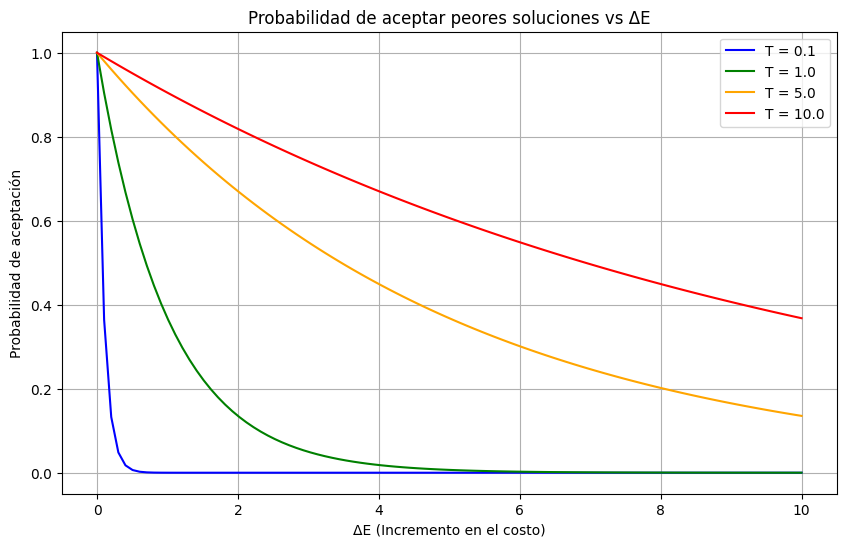

In [2]:
# Configuración de la visualización
deltas = np.linspace(0, 10, 100)  # Diferentes valores de delta_E
temperaturas = [0.1, 1.0, 5.0, 10.0]  # Diferentes temperaturas
colores = ['blue', 'green', 'orange', 'red']

plt.figure(figsize=(10, 6))
for T, color in zip(temperaturas, colores):
    probabilidades = [calcular_probabilidad_aceptacion(d, T) for d in deltas]
    plt.plot(deltas, probabilidades, color=color, label=f'T = {T}')

plt.xlabel('ΔE (Incremento en el costo)')
plt.ylabel('Probabilidad de aceptación')
plt.title('Probabilidad de aceptar peores soluciones vs ΔE')
plt.legend()
plt.grid(True)
plt.show()

Con $T = 0{,}1$ la curva cae a casi cero apenas el costo empeora, de modo que el método prácticamente solo acepta mejoras. Con $T = 10$ la caída es lenta y aun empeoramientos grandes tienen una probabilidad apreciable de aceptarse. La tabla da los valores para tres incrementos concretos.

In [3]:
# Ejemplo numérico
print("Ejemplos numéricos de probabilidades de aceptación:")
print("Delta E  |", end=" ")
for T in temperaturas:
    print(f"T={T:<6} |", end=" ")
print("\n" + "-"*50)

for delta in [1, 2, 5]:
    print(f"{delta:<8} |", end=" ")
    for T in temperaturas:
        prob = calcular_probabilidad_aceptacion(delta, T)
        print(f"{prob:.4f} |", end=" ")
    print()

Ejemplos numéricos de probabilidades de aceptación:
Delta E  | T=0.1    | T=1.0    | T=5.0    | T=10.0   | 
--------------------------------------------------
1        | 0.0000 | 0.3679 | 0.8187 | 0.9048 | 
2        | 0.0000 | 0.1353 | 0.6703 | 0.8187 | 
5        | 0.0000 | 0.0067 | 0.3679 | 0.6065 | 


La probabilidad depende solo del cociente $\Delta E / T$. Por eso la temperatura tiene que elegirse en la escala de las diferencias de costo del problema, algo que vuelve a aparecer en el último ejemplo del capítulo.

## Minimización de la función de Rosenbrock

El segundo ejemplo minimiza la función de Rosenbrock en dos variables,

$$f(x) = (1 - x_1)^2 + 100\,(x_2 - x_1^2)^2,$$

cuyo mínimo global es $f = 0$ en $x = (1, 1)$, al fondo de un valle curvo y estrecho. La solución es un vector real $x = (x_1, x_2)$. La solución vecina se obtiene sumando a cada componente una perturbación normal,

$$x' = x + \varepsilon, \qquad \varepsilon_i \sim \mathcal{N}(0,\ 0{,}1^2),$$

y la temperatura se multiplica por $\alpha$ en cada iteración. La función guarda la mejor solución encontrada, que puede no coincidir con la última aceptada, y el historial de soluciones actuales.

In [4]:
def funcion_objetivo(x):
    """
    Función objetivo a minimizar
    En este ejemplo usamos la función de Rosenbrock
    """
    return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2

def recocido_simulado(f, x0, T0=1000, alpha=0.95, n_iter=1000):
    """
    Implementación del algoritmo de recocido simulado

    Parámetros:
    f: función objetivo a minimizar
    x0: punto inicial
    T0: temperatura inicial
    alpha: factor de enfriamiento
    n_iter: número máximo de iteraciones
    """
    x_actual = x0
    f_actual = f(x_actual)
    x_mejor = x_actual
    f_mejor = f_actual
    T = T0

    # Listas para guardar el historial
    historial_x = [x_actual]
    historial_f = [f_actual]

    for i in range(n_iter):
        # Generar solución vecina
        x_nuevo = x_actual + np.random.normal(0, 0.1, size=len(x_actual))
        f_nuevo = f(x_nuevo)

        # Calcular diferencia de energía
        delta_E = f_nuevo - f_actual

        # Criterio de aceptación de Metropolis
        if delta_E < 0 or np.random.random() < np.exp(-delta_E/T):
            x_actual = x_nuevo
            f_actual = f_nuevo

            # Actualizar mejor solución encontrada
            if f_actual < f_mejor:
                x_mejor = x_actual
                f_mejor = f_actual

        # Guardar historial
        historial_x.append(x_actual)
        historial_f.append(f_actual)

        # Enfriar temperatura
        T = T * alpha

    return x_mejor, f_mejor, historial_x, historial_f

Se parte de un punto aleatorio en $[-5, 5]^2$ con los valores por omisión: $T_0 = 1000$, $\alpha = 0{,}95$ y 1000 iteraciones.

In [5]:
random.seed(42)
np.random.seed(42)

# Punto inicial aleatorio
x0 = np.random.uniform(-5, 5, size=2)

# Ejecutar recocido simulado
x_opt, f_opt, historial_x, historial_f = recocido_simulado(funcion_objetivo, x0)

print("Punto inicial:", x0)
print("Solución encontrada:", x_opt)
print("Valor de la función en la mejor solución:", f_opt)

Punto inicial: [-1.25459881  4.50714306]
Solución encontrada: [-1.66173102  2.7425879 ]
Valor de la función en la mejor solución: 7.120013586442145


La figura superior muestra las curvas de nivel de la función, el punto inicial, la mejor solución y la trayectoria de soluciones aceptadas; la inferior, el valor de la función en la solución actual a lo largo de las iteraciones.

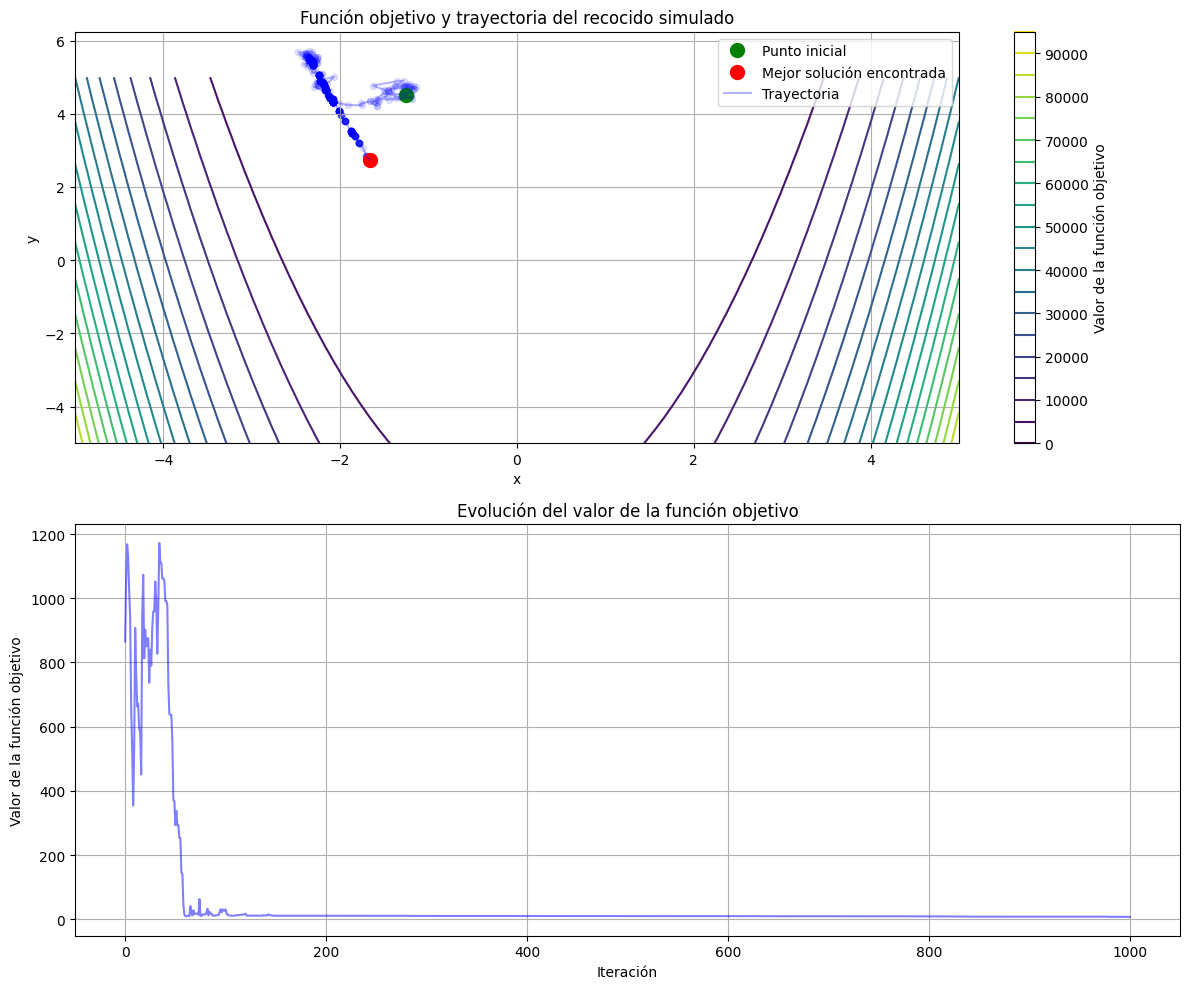

In [6]:
# Visualización de la función y la trayectoria
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = np.zeros_like(X)

# Calcular valores de la función objetivo
for i in range(len(x)):
    for j in range(len(y)):
        Z[i,j] = funcion_objetivo(np.array([X[i,j], Y[i,j]]))

# Crear gráfico
plt.figure(figsize=(12,10))

# Subplot para la vista superior
plt.subplot(2,1,1)
plt.contour(X, Y, Z, levels=20)
plt.colorbar(label='Valor de la función objetivo')

# Marcar punto inicial
plt.plot(x0[0], x0[1], 'go', label='Punto inicial', markersize=10)

# Marcar la mejor solución encontrada
plt.plot(x_opt[0], x_opt[1], 'ro', label='Mejor solución encontrada', markersize=10)

# Marcar todas las soluciones visitadas
historial_x = np.array(historial_x)
plt.plot(historial_x[:,0], historial_x[:,1], 'b-', alpha=0.3, label='Trayectoria')
plt.scatter(historial_x[:,0], historial_x[:,1], c='blue', alpha=0.1, s=20)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Función objetivo y trayectoria del recocido simulado')
plt.legend()
plt.grid(True)

# Subplot para la evolución del valor de la función
plt.subplot(2,1,2)
plt.plot(historial_f, 'b-', alpha=0.5)
plt.xlabel('Iteración')
plt.ylabel('Valor de la función objetivo')
plt.title('Evolución del valor de la función objetivo')
plt.grid(True)

plt.tight_layout()
plt.show()

El valor de la función cae rápido en las primeras iteraciones, mientras la trayectoria llega al valle, y después se estabiliza. La mejor solución encontrada queda dentro del valle, pero lejos del mínimo $(1, 1)$. La razón está en el enfriamiento. Como $T_k = 1000 \cdot 0{,}95^k$, la temperatura es menor que 1 a partir de $k \approx 135$, y desde ese momento el método acepta prácticamente solo mejoras. Avanza entonces por el fondo del valle con pasos de desviación estándar 0,1, y como ese fondo es curvo y casi plano, las mejoras son pequeñas. Un enfriamiento más lento, con un $\alpha$ más cercano a 1, o más iteraciones dejan más tiempo para recorrer el valle.

## El problema de las $n$ reinas

El tercer ejemplo busca ubicar $n$ reinas en un tablero de $n \times n$ sin que ninguna ataque a otra. La solución se representa como una permutación $s$ de $\{0, \dots, n-1\}$, en la que el índice es la columna y el valor $s_i$ es la fila de la reina de esa columna. Con esta representación nunca hay dos reinas en la misma fila ni en la misma columna, así que el costo solo cuenta los pares que se atacan en diagonal,

$$c(s) = \left|\{(i, j) : i < j,\ |s_i - s_j| = |i - j|\}\right|,$$

y una solución es factible cuando $c(s) = 0$. La solución vecina se obtiene intercambiando los valores de dos posiciones distintas elegidas al azar, un movimiento que conserva la permutación.

In [7]:
def crear_tablero_inicial(n):
    """
    Crea una solución inicial aleatoria para el problema de las n reinas.

    Args:
        n (int): Tamaño del tablero (n x n)

    Returns:
        numpy.array: Vector de posiciones donde el índice representa la columna
                    y el valor representa la fila donde está ubicada la reina
    """
    return np.random.permutation(n)

def calcular_conflictos(estado):
    """
    Calcula el número de pares de reinas que se atacan entre sí.

    Args:
        estado (numpy.array): Vector que representa las posiciones de las reinas

    Returns:
        int: Número de conflictos (pares de reinas que se atacan)
    """
    n = len(estado)
    conflictos = 0

    for i in range(n):
        for j in range(i + 1, n):
            # Verifica ataques en diagonal
            if abs(estado[i] - estado[j]) == abs(i - j):
                conflictos += 1

    return conflictos

def generar_vecino(estado):
    """
    Genera una solución vecina intercambiando la posición de dos reinas al azar.

    Args:
        estado (numpy.array): Estado actual del tablero

    Returns:
        numpy.array: Nuevo estado con dos reinas intercambiadas
    """
    nuevo_estado = estado.copy()
    n = len(estado)
    i, j = random.sample(range(n), 2)  # dos posiciones distintas
    nuevo_estado[i], nuevo_estado[j] = nuevo_estado[j], nuevo_estado[i]
    return nuevo_estado

def visualizar_tablero(estado, titulo=""):
    """
    Visualiza el tablero de ajedrez con las reinas.

    Args:
        estado (numpy.array): Vector que representa las posiciones de las reinas
        titulo (str): Título para la visualización
    """
    n = len(estado)
    tablero = np.zeros((n, n))

    # Coloca las reinas en el tablero
    for col, fila in enumerate(estado):
        tablero[fila][col] = 1

    plt.figure(figsize=(8, 8))
    plt.imshow(tablero, cmap='binary')
    plt.grid(True)
    plt.title(titulo)
    plt.show()

El ciclo principal se detiene por cualquiera de tres condiciones: la temperatura baja de $T_{\min}$, el número de iteraciones seguidas sin mejorar la mejor solución llega a `max_iter`, o se encuentra una solución sin conflictos. La temperatura baja en cada iteración con el factor $\alpha$.

In [8]:
def recocido_simulado_n_reinas(n, T0=100.0, Tmin=0.01, alpha=0.95, max_iter=10000):
    """
    Implementa el algoritmo de recocido simulado para resolver el problema de las n reinas.

    Args:
        n (int): Tamaño del tablero (n x n)
        T0 (float): Temperatura inicial
        Tmin (float): Temperatura mínima
        alpha (float): Factor de enfriamiento
        max_iter (int): Número máximo de iteraciones

    Returns:
        tuple: (mejor_estado, mejor_costo, historial_costos)
    """
    # Inicialización
    estado_actual = crear_tablero_inicial(n)
    costo_actual = calcular_conflictos(estado_actual)
    mejor_estado = estado_actual.copy()
    mejor_costo = costo_actual

    T = T0
    historial_costos = [costo_actual]

    # Bucle principal del recocido simulado
    iter_sin_mejora = 0

    while T > Tmin and iter_sin_mejora < max_iter:
        # Generar solución vecina
        estado_vecino = generar_vecino(estado_actual)
        costo_vecino = calcular_conflictos(estado_vecino)

        # Calcular diferencia de energía
        delta_E = costo_vecino - costo_actual

        # Criterio de aceptación de Metropolis
        if delta_E < 0 or np.random.random() < np.exp(-delta_E / T):
            estado_actual = estado_vecino
            costo_actual = costo_vecino

            # Actualizar mejor solución encontrada
            if costo_actual < mejor_costo:
                mejor_estado = estado_actual.copy()
                mejor_costo = costo_actual
                iter_sin_mejora = 0
            else:
                iter_sin_mejora += 1
        else:
            iter_sin_mejora += 1

        # Enfriar temperatura
        T *= alpha
        historial_costos.append(costo_actual)

        # Si encontramos una solución perfecta, terminamos
        if mejor_costo == 0:
            break

    return mejor_estado, mejor_costo, historial_costos

El ejemplo resuelve el tablero clásico de $8 \times 8$ con los parámetros por omisión.

In [9]:
random.seed(42)
np.random.seed(42)

# Parámetros del problema
n = 8  # Tamaño del tablero

# Ejecutar el algoritmo
mejor_estado, mejor_costo, historial = recocido_simulado_n_reinas(n)

# Mostrar resultados
print("Mejor solución encontrada:")
print(f"Número de conflictos: {mejor_costo}")
print(f"Posiciones de las reinas: {mejor_estado}")
print(f"Iteraciones: {len(historial) - 1}")

Mejor solución encontrada:
Número de conflictos: 0
Posiciones de las reinas: [5 2 4 6 0 3 1 7]
Iteraciones: 56


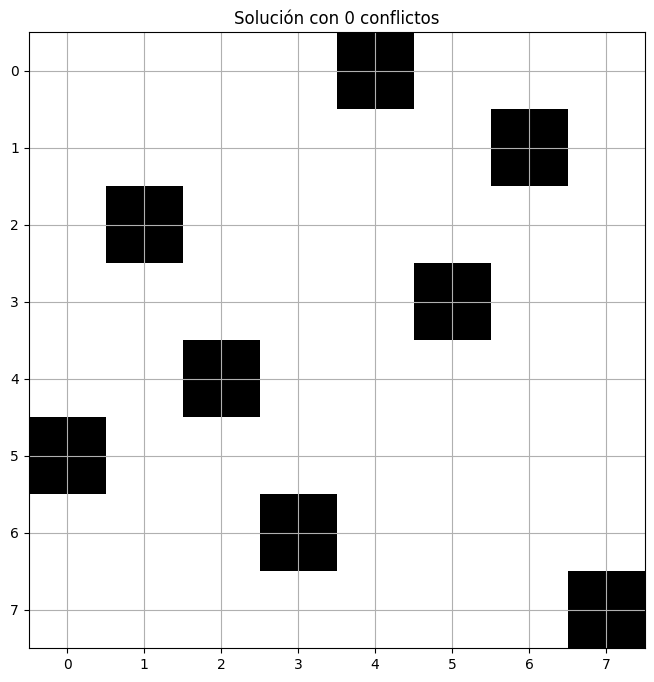

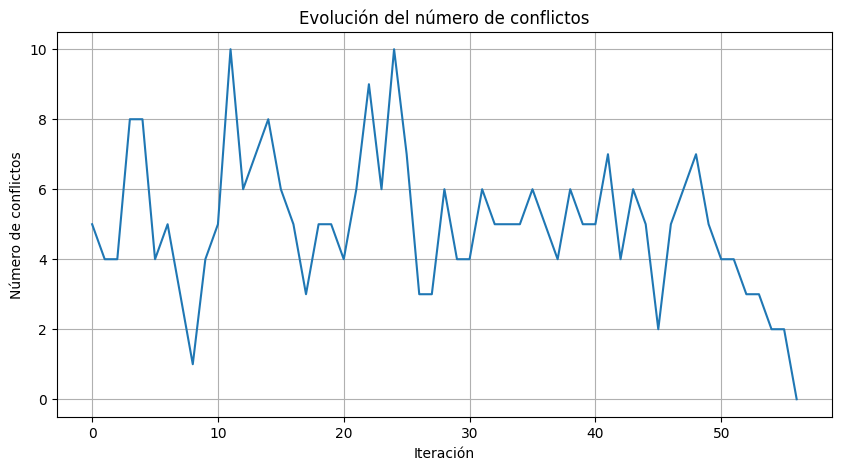

In [10]:
# Visualizar solución
visualizar_tablero(mejor_estado, f"Solución con {mejor_costo} conflictos")

# Graficar evolución del costo
plt.figure(figsize=(10, 5))
plt.plot(historial)
plt.xlabel('Iteración')
plt.ylabel('Número de conflictos')
plt.title('Evolución del número de conflictos')
plt.grid(True)
plt.show()

En esta corrida el método encuentra una ubicación sin conflictos en la iteración 56, cuando la temperatura todavía es alta ($100 \cdot 0{,}95^{56} \approx 5{,}7$). Durante toda la corrida el número de conflictos sube y baja, porque con esa temperatura se aceptan muchos intercambios que empeoran el tablero. La búsqueda se detiene en cuanto visita un tablero sin conflictos, antes de llegar a la fase en la que solo se aceptan mejoras.

Con $T_0 = 100$, $T_{\min} = 0{,}01$ y $\alpha = 0{,}95$, la condición $T > T_{\min}$ permite como máximo unas 180 iteraciones, porque $100 \cdot 0{,}95^k < 0{,}01$ desde $k \approx 180$, así que el límite de 10 000 iteraciones sin mejora nunca llega a actuar. Para tableros más grandes ese presupuesto se queda corto y hace falta enfriar más despacio. El script original usa $n = 10\,000$. Como el cálculo de conflictos recorre todos los pares de reinas, cada evaluación crece con $n^2$, y en 180 iteraciones el método solo alcanza a hacer unos pocos intercambios en un tablero de ese tamaño; por eso el cuaderno usa $n = 8$.

## Ajuste de hiperparámetros de un bosque aleatorio

El último ejemplo usa el recocido simulado para elegir los hiperparámetros de un bosque aleatorio (*random forest*) de regresión sobre el conjunto de datos de vivienda de California (*California Housing*), que `scikit-learn` descarga la primera vez. La solución es un vector de cuatro hiperparámetros,

$$x = (\texttt{n\_estimators},\ \texttt{max\_depth},\ \texttt{min\_samples\_split},\ \texttt{min\_samples\_leaf}),$$

con límites $[10, 200]$, $[3, 20]$, $[2, 20]$ y $[1, 10]$. La búsqueda trata cada componente como un número real, de modo que los pasos pequeños se acumulan, y lo redondea al entero más cercano solo al construir el modelo. El costo de una solución es el error cuadrático medio (MSE) del bosque entrenado con esos hiperparámetros y evaluado en un conjunto de validación,

$$\text{MSE} = \frac{1}{m}\sum_{k=1}^{m} (y_k - \hat{y}_k)^2.$$

El conjunto de validación se separa del de entrenamiento y no comparte registros con el de prueba. Si el recocido se guiara por el MSE de prueba, los hiperparámetros quedarían ajustados a ese conjunto y su MSE subestimaría el error del modelo con datos nuevos. Por eso la búsqueda solo ve el MSE de validación, y el conjunto de prueba se usa una sola vez, al final, para informar el error de la configuración elegida.

A diferencia de los ejemplos anteriores, evaluar una solución cuesta entrenar un modelo completo, de modo que el número de evaluaciones manda sobre el tiempo de cómputo.

In [11]:
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

def cargar_datos():
    """Carga y prepara los datos de California Housing"""
    housing = fetch_california_housing()
    X_train, X_test, y_train, y_test = train_test_split(
        housing.data, housing.target, test_size=0.2, random_state=42
    )
    return X_train, X_test, y_train, y_test

def evaluar_modelo(params, X_train, X_eval, y_train, y_eval):
    """
    Entrena el RandomForest con los parámetros dados (redondeados a entero)
    Retorna el error cuadrático medio en el conjunto de evaluación (para minimización)
    """
    rf = RandomForestRegressor(
        n_estimators=int(round(params[0])),
        max_depth=int(round(params[1])),
        min_samples_split=int(round(params[2])),
        min_samples_leaf=int(round(params[3])),
        random_state=42
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_eval)
    return mean_squared_error(y_eval, y_pred)

### Versión con un operador de vecindad

La función `generar_vecino` elige al azar uno de los cuatro hiperparámetros, le suma un desplazamiento uniforme de hasta el 10 % del ancho de su intervalo y recorta el resultado a los límites,

$$x'_j = \min\{\max\{x_j + u\,(b_j - a_j),\ a_j\},\ b_j\}, \qquad u \sim \mathcal{U}(-0{,}1;\ 0{,}1),$$

donde $[a_j, b_j]$ es el intervalo del hiperparámetro $j$. A diferencia de los ejemplos anteriores, la temperatura no baja en cada iteración, sino cada `max_iter` iteraciones, y la búsqueda termina cuando $T$ llega a $T_{\min}$ o cuando se completan `max_iter_total` evaluaciones. El punto de partida es $(100, 10, 10, 5)$.

In [12]:
def generar_vecino(params, limites):
    """Genera una solución vecina modificando aleatoriamente los parámetros"""
    nuevo_params = params.copy()
    idx = np.random.randint(0, len(params))
    delta = np.random.uniform(-0.1, 0.1) * (limites[idx][1] - limites[idx][0])
    nuevo_params[idx] += delta
    nuevo_params[idx] = np.clip(nuevo_params[idx], limites[idx][0], limites[idx][1])
    return nuevo_params

def recocido_simulado_rf(X_train, X_val, y_train, y_val, T0=100.0, Tmin=0.1, alpha=0.95, max_iter=100, max_iter_total=1000):
    """
    Optimiza los hiperparámetros de RandomForest usando recocido simulado

    Parámetros a optimizar:
    - n_estimators: [10, 200]
    - max_depth: [3, 20]
    - min_samples_split: [2, 20]
    - min_samples_leaf: [1, 10]
    """
    # Límites de los parámetros
    limites = [
        [10, 200],   # n_estimators
        [3, 20],     # max_depth
        [2, 20],     # min_samples_split
        [1, 10]      # min_samples_leaf
    ]

    # Inicialización (vector de tipo flotante para que los pasos pequeños no se trunquen)
    params_actual = np.array([
        100,  # n_estimators inicial
        10,   # max_depth inicial
        10,   # min_samples_split inicial
        5     # min_samples_leaf inicial
    ], dtype=float)

    costo_actual = evaluar_modelo(params_actual, X_train, X_val, y_train, y_val)
    mejor_params = params_actual.copy()
    mejor_costo = costo_actual

    T = T0
    historial_costos = [costo_actual]
    iter_total = 0

    print("\nIniciando búsqueda...")
    print("Iteración | Temperatura | Mejor MSE | MSE Actual")
    print("-" * 50)

    while T > Tmin and iter_total < max_iter_total:
        for _ in range(max_iter):
            params_vecino = generar_vecino(params_actual, limites)
            costo_vecino = evaluar_modelo(params_vecino, X_train, X_val, y_train, y_val)

            delta_E = costo_vecino - costo_actual

            if delta_E < 0 or np.random.random() < np.exp(-delta_E / T):
                params_actual = params_vecino
                costo_actual = costo_vecino

                if costo_actual < mejor_costo:
                    mejor_params = params_actual.copy()
                    mejor_costo = costo_actual

            historial_costos.append(costo_actual)
            iter_total += 1

            if iter_total % 10 == 0:  # Mostrar progreso cada 10 iteraciones
                print(f"{iter_total:^9d} | {T:^11.4f} | {mejor_costo:^9.4f} | {costo_actual:^10.4f}")

            if iter_total >= max_iter_total:
                break

        T *= alpha

    print("\nBúsqueda finalizada!")
    return mejor_params, mejor_costo, historial_costos

Antes de la búsqueda, `train_test_split` separa, con semilla fija, el 25 % del conjunto de entrenamiento como conjunto de validación (4128 registros). Cada evaluación entrena un bosque de hasta 200 árboles, así que, para que el cuaderno corra en poco tiempo, el ejemplo entrena con los primeros 2000 registros que quedan para entrenamiento (que `train_test_split` ya barajó) y limita la búsqueda a 60 evaluaciones, con 10 evaluaciones por temperatura. La reducción se aplica después de la partición, de modo que los conjuntos de validación y de prueba se conservan completos. El script original usa los 16 512 registros de entrenamiento y 500 evaluaciones con 100 por temperatura; con esos valores la búsqueda toma bastante más tiempo y los errores son menores, porque el modelo se entrena con más datos.

In [13]:
random.seed(42)
np.random.seed(42)

# Cargar datos
print("Cargando datos...")
X_train, X_test, y_train, y_test = cargar_datos()

# Conjunto de validación separado del de entrenamiento (25 %)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

# Submuestra de entrenamiento para reducir el tiempo de cómputo
X_train, y_train = X_train[:2000], y_train[:2000]

# Ejecutar optimización (guiada por el MSE de validación)
mejor_params, mejor_costo, historial = recocido_simulado_rf(
    X_train, X_val, y_train, y_val, max_iter=10, max_iter_total=60
)

# Mostrar resultados
print("\nMejores hiperparámetros encontrados:")
print(f"n_estimators: {int(round(mejor_params[0]))}")
print(f"max_depth: {int(round(mejor_params[1]))}")
print(f"min_samples_split: {int(round(mejor_params[2]))}")
print(f"min_samples_leaf: {int(round(mejor_params[3]))}")
print(f"\nMejor MSE de validación: {mejor_costo:.4f}")

# Evaluación final en el conjunto de prueba, una sola vez
mse_prueba = evaluar_modelo(mejor_params, X_train, X_test, y_train, y_test)
print(f"MSE de prueba de la mejor configuración: {mse_prueba:.4f}")

Cargando datos...



Iniciando búsqueda...
Iteración | Temperatura | Mejor MSE | MSE Actual
--------------------------------------------------


   10     |  100.0000   |  0.3532   |   0.3619  


   20     |   95.0000   |  0.3532   |   0.3841  


   30     |   90.2500   |  0.3532   |   0.3705  


   40     |   85.7375   |  0.3532   |   0.3690  


   50     |   81.4506   |  0.3532   |   0.3840  


   60     |   77.3781   |  0.3532   |   0.5014  

Búsqueda finalizada!

Mejores hiperparámetros encontrados:
n_estimators: 100
max_depth: 10
min_samples_split: 10
min_samples_leaf: 5

Mejor MSE de validación: 0.3532


MSE de prueba de la mejor configuración: 0.3577


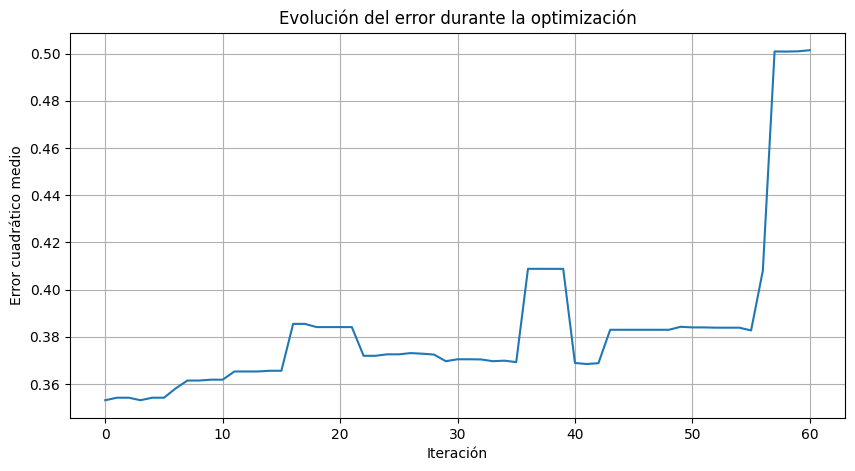

In [14]:
# Graficar evolución del costo
plt.figure(figsize=(10, 5))
plt.plot(historial)
plt.xlabel('Iteración')
plt.ylabel('Error cuadrático medio')
plt.title('Evolución del error durante la optimización')
plt.grid(True)
plt.show()

En esta corrida ninguna de las 60 soluciones visitadas mejora el punto de partida, así que la mejor configuración es la inicial, $(100, 10, 10, 5)$, con un MSE de validación de 0,3532 y un MSE de prueba de 0,3577. El MSE de la solución actual, en cambio, sube y se queda en valores peores, entre 0,35 y 0,41 durante casi toda la búsqueda y cerca de 0,50 en las últimas evaluaciones. La explicación está en la escala de la temperatura. En la salida, las diferencias de MSE entre soluciones son de centésimas o de décimas, y con $T$ entre 100 y 77 la probabilidad $e^{-\Delta E/T}$ es prácticamente 1 para cualquier empeoramiento. Con esa temperatura el método se comporta como una caminata aleatoria y la búsqueda solo aprovecha lo que encuentra a través de la mejor solución que guarda. Las diapositivas recomiendan una temperatura inicial mayor que las diferencias de costo entre un mínimo local y sus vecinos; aquí es varios órdenes de magnitud mayor, y para que el criterio de Metropolis discrimine entre empeoramientos pequeños y grandes, $T_0$ tiene que estar más cerca de la escala de esas diferencias.

### Variante con varios operadores de vecindad

La segunda versión cambia el vecindario. En cada iteración elige al azar uno de tres operadores:

- incremento o decremento, que suma o resta el 10 % del valor actual de un hiperparámetro elegido al azar, sin bajar de 1;
- intercambio (*swap*), que intercambia los valores de dos hiperparámetros distintos;
- reinicio (*reset*), que asigna a un hiperparámetro un valor uniforme dentro de sus límites.

Después de aplicar el operador, todos los hiperparámetros se recortan a sus límites. La temperatura baja cada `max_iter` iteraciones y la búsqueda termina cuando $T$ llega a $T_{\min}$.

El archivo de esta variante usa la función `evaluar_modelo` del primero, pero llama además a `generar_solucion_inicial` y a la lista `limites`, que no están definidas en ninguno de los dos archivos. La celda siguiente las define con los mismos límites y el mismo punto de partida de la primera versión, para que la comparación sea justa.

In [15]:
# Definiciones que la variante necesita y que no están en los scripts originales
limites = [
    [10, 200],   # n_estimators
    [3, 20],     # max_depth
    [2, 20],     # min_samples_split
    [1, 10]      # min_samples_leaf
]

def generar_solucion_inicial():
    """Punto de partida igual al de recocido_simulado_rf"""
    return np.array([100, 10, 10, 5], dtype=float)

In [16]:
def recocido_simulado_rf_mejorado(X_train, X_val, y_train, y_val,
                                 T0=100.0, Tmin=0.01, alpha=0.95, max_iter=100):
    """
    Versión mejorada del recocido simulado con diferentes operadores de vecindad
    """
    # Inicialización
    params_actual = generar_solucion_inicial()
    costo_actual = evaluar_modelo(params_actual, X_train, X_val, y_train, y_val)
    mejor_params = params_actual.copy()
    mejor_costo = costo_actual

    T = T0
    historial_costos = [costo_actual]

    # Operadores de vecindad
    def operador_incremento_decremental(params):
        """Incrementa o decrementa un parámetro en una cantidad pequeña"""
        nuevo_params = params.copy()
        param_idx = np.random.randint(0, len(params))
        delta = np.random.choice([-0.1, 0.1]) * params[param_idx]
        nuevo_params[param_idx] = max(1, params[param_idx] + delta)
        return nuevo_params

    def operador_swap(params):
        """Intercambia valores entre dos parámetros"""
        nuevo_params = params.copy()
        i, j = np.random.choice(len(params), 2, replace=False)
        nuevo_params[i], nuevo_params[j] = nuevo_params[j], nuevo_params[i]
        return nuevo_params

    def operador_reset(params):
        """Reinicia un parámetro a un valor aleatorio dentro de sus límites"""
        nuevo_params = params.copy()
        param_idx = np.random.randint(0, len(params))
        nuevo_params[param_idx] = np.random.uniform(limites[param_idx][0],
                                                  limites[param_idx][1])
        return nuevo_params

    operadores = [operador_incremento_decremental, operador_swap, operador_reset]

    while T > Tmin:
        for _ in range(max_iter):
            # Seleccionar operador de vecindad aleatoriamente
            operador = np.random.choice(operadores)
            params_vecino = operador(params_actual)

            # Asegurar que los parámetros estén dentro de los límites
            for i, (min_val, max_val) in enumerate(limites):
                params_vecino[i] = np.clip(params_vecino[i], min_val, max_val)

            costo_vecino = evaluar_modelo(params_vecino, X_train, X_val,
                                        y_train, y_val)

            delta_E = costo_vecino - costo_actual

            # Criterio de aceptación de Metropolis
            if delta_E < 0 or np.random.random() < np.exp(-delta_E / T):
                params_actual = params_vecino
                costo_actual = costo_vecino

                if costo_actual < mejor_costo:
                    mejor_params = params_actual.copy()
                    mejor_costo = costo_actual

            historial_costos.append(costo_actual)

        T *= alpha

    return mejor_params, mejor_costo, historial_costos

Para que las dos versiones gasten el mismo número de evaluaciones, la variante se corre con 10 evaluaciones por temperatura y $T_{\min} = 75$. Con $T_0 = 100$ y $\alpha = 0{,}95$ eso da seis niveles de temperatura y 60 evaluaciones, igual que la primera versión. Con los valores por omisión del script ($T_{\min} = 0{,}01$ y 100 evaluaciones por temperatura) la búsqueda haría unas 18 000 evaluaciones.

In [17]:
random.seed(42)
np.random.seed(42)

# Probar la versión mejorada
print("Ejecutando versión mejorada con múltiples operadores de vecindad...")
mejor_params_mejorado, mejor_costo_mejorado, historial_mejorado = \
    recocido_simulado_rf_mejorado(X_train, X_val, y_train, y_val, Tmin=75, max_iter=10)

print("\nResultados con operadores de vecindad mejorados:")
print(f"n_estimators: {int(round(mejor_params_mejorado[0]))}")
print(f"max_depth: {int(round(mejor_params_mejorado[1]))}")
print(f"min_samples_split: {int(round(mejor_params_mejorado[2]))}")
print(f"min_samples_leaf: {int(round(mejor_params_mejorado[3]))}")
print(f"\nMejor MSE de validación: {mejor_costo_mejorado:.4f}")

# Evaluación final en el conjunto de prueba, una sola vez
mse_prueba_mejorado = evaluar_modelo(mejor_params_mejorado, X_train, X_test, y_train, y_test)
print(f"MSE de prueba de la mejor configuración: {mse_prueba_mejorado:.4f}")

Ejecutando versión mejorada con múltiples operadores de vecindad...



Resultados con operadores de vecindad mejorados:
n_estimators: 100
max_depth: 10
min_samples_split: 10
min_samples_leaf: 5

Mejor MSE de validación: 0.3532


MSE de prueba de la mejor configuración: 0.3577


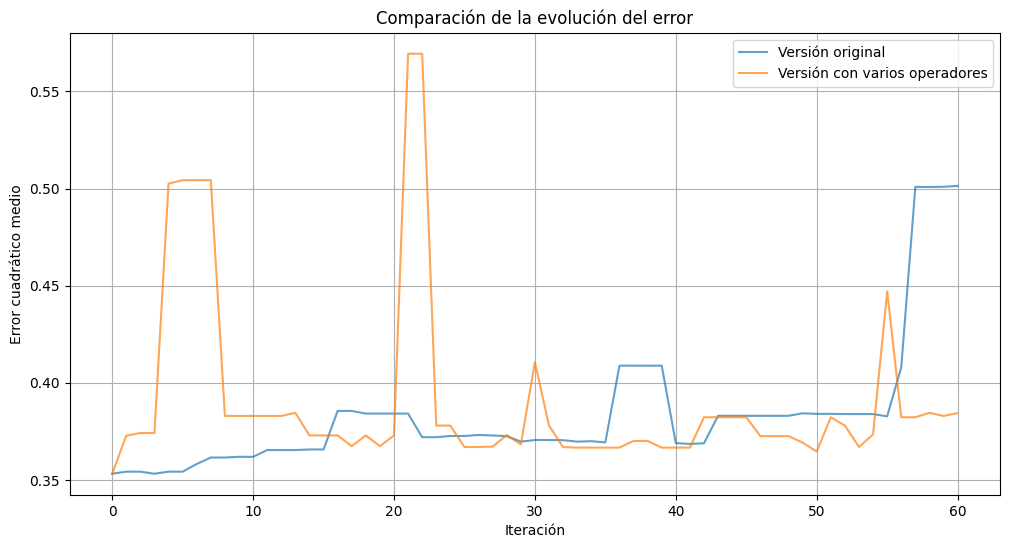

In [18]:
# Comparar evolución del costo
plt.figure(figsize=(12, 6))
plt.plot(historial, label='Versión original', alpha=0.7)
plt.plot(historial_mejorado, label='Versión con varios operadores', alpha=0.7)
plt.xlabel('Iteración')
plt.ylabel('Error cuadrático medio')
plt.title('Comparación de la evolución del error')
plt.legend()
plt.grid(True)
plt.show()

Con el mismo número de evaluaciones, la variante con tres operadores da saltos más grandes en el MSE de la solución actual, lo que es coherente con operadores como el reinicio y el intercambio, que pueden llevar un hiperparámetro de un extremo a otro de su intervalo. En esta corrida ninguna de las soluciones visitadas mejora el punto de partida, de modo que la mejor solución que devuelve es la inicial, la misma de la primera versión y con el mismo MSE de prueba. Como en la primera versión, la temperatura está muy por encima de las diferencias de MSE y casi todos los movimientos se aceptan, así que la comparación entre los dos vecindarios dice poco mientras no se ajuste la escala de $T$. El operador de intercambio, además, mezcla hiperparámetros de naturaleza distinta, como el número de árboles y la profundidad máxima, y el recorte posterior a los límites decide buena parte del resultado.

## Referencias

- Nicholas Metropolis, Arianna W. Rosenbluth, Marshall Nicholas Rosenbluth, Augusta H. Teller, and Edward Teller. Equation of state calculations by fast computing machines. *The Journal of Chemical Physics*, 21(6):1087–1092, June 1953.
- Scott Kirkpatrick, Charles Daniel Gelatt, Jr., and Mario P. Vecchi. Optimization by simulated annealing. *Science Magazine*, 220(4598):671–680, May 13, 1983. doi: 10.1126/science.220.4598.671.